# Ground-plane cheesing around a CPW meander

Second, harder test of `GroundPlaneCheese`: a genuinely non-rectangular
keepout shape -- a fillet-jogged meandered CPW readout resonator, not just a
component's own straight bounding box.

Design used: `build_design_cpw.py`, `squid_array_coupling/build_design.py`
with the `SquidArray` removed -- just the `OpenToGround` / `ShortToGround`
launch pads and the `RouteMeander` between them, on the same auto-sized-chip
convention.

This test surfaced three real bugs (see the parent conversation / commit
message for the full diagnosis), all now fixed:

1. `GroundPlaneCheese`'s keepout only checked existing *metal*, never an
   existing *cutout*'s own boundary (e.g. `open_to_ground`'s termination-gap
   poly).
2. Keepout filtering ran in the lattice's local coordinates while the
   design's geometry is in absolute coordinates -- only looked correct by
   coincidence when a chip happened to be centered near the origin.
3. `qmview` (the shared no-GUI preview/sanity-check module used across this
   repo's design notebooks) never read the `path` qgeometry table at all --
   only `poly` and `junction`. A CPW trace/cut is stored as a LineString +
   width in `path`, so `qmview.render`, `qmview.ground_pieces`, and
   `qmview.sanity_checks` were all silently blind to every CPW in every
   notebook that uses them, not just this one. Fixed in
   `qmview.py` (the shared copy in the `qcg-quantum-design` env) to read
   both tables everywhere it reads geometry.


In [1]:
import sys
sys.path.insert(0, '.')

import qmview
from build_design_cpw import build_design
from ground_plane_cheese import GroundPlaneCheese


## Build the bare CPW meander (no SQUID array, no cheesing yet)

In [2]:
design = build_design()

n_metal_nets, min_gap_um, n_ground_pieces = qmview.sanity_checks(design)
print(f"chip size: {design.chips.main.size.size_x} x {design.chips.main.size.size_y}")


metal nets (>300 um2): 1   min gap between them: inf um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
chip size: 2.95mm x 2.305625mm


In [3]:
from qiskit_metal import MetalGUI

gui = MetalGUI(design)

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'before cheesing'}, xlabel='x (mm)', ylabel='y (mm)'>)

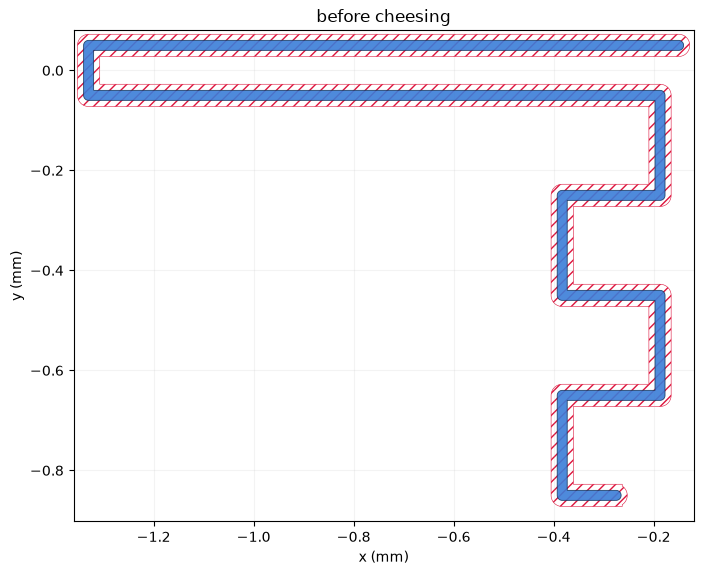

In [3]:
qmview.preview(design, title="before cheesing")


## Apply the cheese

The CPW trace ("trace") and its ground-plane gap ("cut") live in the
`path` qgeometry table, not `poly` -- `GroundPlaneCheese` reads both tables
so the meander's actual shape (not just its bounding box) is respected,
including through the fillet-jogged corner.

In [19]:
ENABLE_CHEESE = True  # opt-in flag -- everything above is unchanged/identical when False

if ENABLE_CHEESE:
    chip_size = design.chips.main.size
    cheese = GroundPlaneCheese(design, 'ground_cheese', options=dict(
        pos_x=chip_size.center_x,
        pos_y=chip_size.center_y,
        width=chip_size.size_x,
        height=chip_size.size_y,
        pitch='35um',
        hole_radius='4um',
        n_sides='12',
        keepout_margin='6um',
    ))
    print(cheese.cheese_report)


GroundPlaneCheese 'ground_cheese': 6600 holes, coverage=0.047, mesh element proxy (n_holes * n_sides)=79200
{'n_holes': 6600, 'coverage': 0.046576644595391424, 'mesh_element_proxy': 79200}


In [20]:
gui.rebuild()

GroundPlaneCheese 'ground_cheese': 6600 holes, coverage=0.047, mesh element proxy (n_holes * n_sides)=79200


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'after cheesing'}, xlabel='x (mm)', ylabel='y (mm)'>)

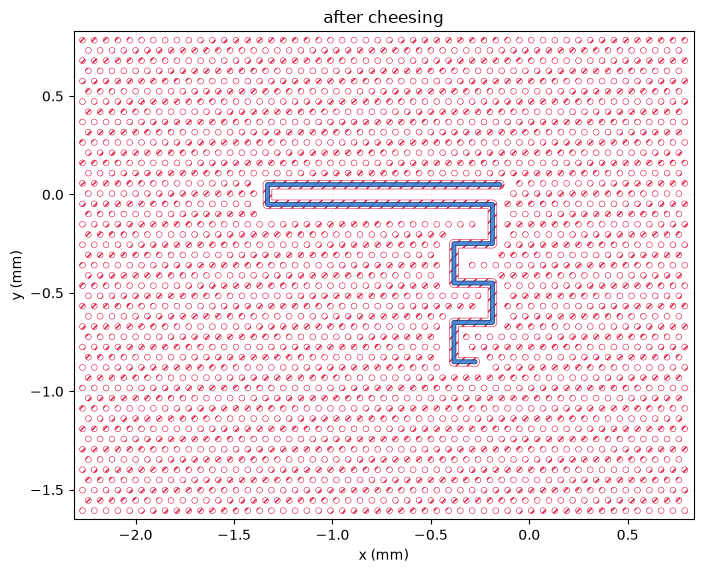

In [5]:
qmview.preview(design, title="after cheesing")


## Zoom on the jog + launch-pad corner

The trace is only 20um wide -- invisible at full-chip scale. Zoom on the
`OpenToGround` launch pad / jog region to actually see the keepout hugging
the meander and the pad's own gap poly.

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'zoom: launch pad + jog'}, xlabel='x (mm)', ylabel='y (mm)'>)

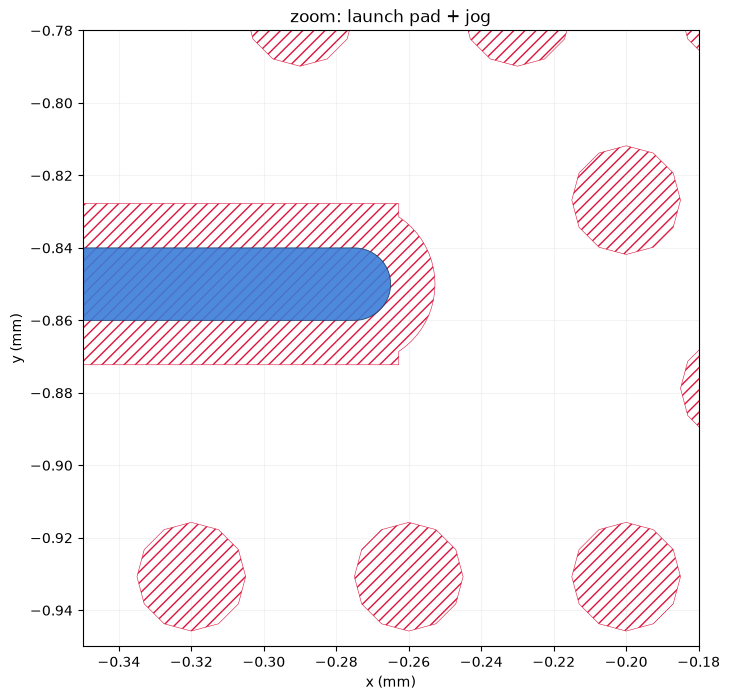

In [6]:
qmview.preview(design, title="zoom: launch pad + jog", xlim=(-0.35, -0.18), ylim=(-0.95, -0.78))


## Quantitative checks

Measured, not eyeballed: the closest cheese hole to the actual CPW trace
metal, and to `open_to_ground`'s own gap poly, should both be at least
`keepout_margin` away -- and the ground plane should still be one piece.

In [7]:
poly = design.qgeometry.tables['poly']
path = design.qgeometry.tables['path']
holes = poly[poly['name'].str.startswith('cheese_holes')]['geometry']

trace_row = path[path['name'] == 'trace'].iloc[0]
trace_metal = trace_row['geometry'].buffer(trace_row['width'] / 2)
min_trace_um = min(h.distance(trace_metal) for h in holes) * 1000

otg_poly = poly[poly['name'] == 'open_to_ground'].iloc[0]['geometry']
min_otg_um = min(h.distance(otg_poly) for h in holes) * 1000

margin_um = float(str(cheese.options.keepout_margin)[:-2])
print(f"keepout_margin: {margin_um} um")
print(f"min hole-to-CPW-trace clearance: {min_trace_um:.2f} um")
print(f"min hole-to-open_to_ground-pad clearance: {min_otg_um:.2f} um")
assert min_trace_um >= margin_um - 1e-6
assert min_otg_um >= margin_um - 1e-6

n_metal_nets, min_gap_um, n_ground_pieces = qmview.sanity_checks(design)
assert n_ground_pieces == 1, "ground plane fragmented -- GroundPlaneCheese.make() should have already raised on this"


keepout_margin: 20.0 um
min hole-to-CPW-trace clearance: 33.49 um
min hole-to-open_to_ground-pad clearance: 40.49 um
metal nets (>300 um2): 1   min gap between them: inf um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
